# Feature Engineering and Vehicle Exploration

In [86]:
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

VALID_CURRENCY = r"(\$|£|€|¥|₹|R|SFr\.|CHF|USD|GBP|EUR|ZAR|CAD|AUD)"

In [87]:
# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

#Set visual style
sns.set_theme(style='whitegrid')


# Load the data
df = pd.read_csv('../data/logbook_assignment1.csv') # Change to fit your structure

C:\Users\adivh\AppData\Local\Temp\ipykernel_32140\898025503.py:10: DtypeWarning: Columns (0: gallons, 1: mpg) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../data/logbook_assignment1.csv') # Change to fit your structure


# Question 2: Feature Engineering



##### 2.1. A new column was created to store currency, the currency had to be extracted from "total_spent" column.  

In [88]:
# 2.1
# Create column currency and into it extract currency from total_spent
df["currency"] = (df["total_spent"]
                  .astype(str)
                  .str.extract(VALID_CURRENCY, flags=re.IGNORECASE, expand=False))

##### 2.2. Columns carrying float values for total_spent and cos per gallon are added.

In [89]:
# 2.2
#Column containing float value for total_spent and cost per gallon
# Extract float vals for _spent and cost per gallon
def money_to_float(val):
    if pd.isna(val):
        return np.nan

    # remove alphabets, symbols, dots, etc
    clean = re.sub(r"^\d\.", "", str(val))
    #multiple dots due to currency abbr
    parts = clean.split(".")
    if len(parts) > 2:
        clean = "".join(parts[:-1]) + "." + parts[-1]
    try:
        return float(clean)
    except ValueError:
        return np.nan

df["total_spent_float"] = df["total_spent"].apply(money_to_float)
df["cost_per_gallon_float"] = df["cost_per_gallon"].apply(money_to_float)

##### 2.3. Given the URL from data, separate into Car year, Model, Make, User ID

In [90]:
# 3. Parse Make, Model, Year, and User ID from URL
# Hint: URL: https://www.somewebsite.com/suzuki/swift/2015/674857

url_split = df["user_url"].astype(str).str.rstrip("/").str.split("/")

df["user_id"] = url_split.str[-1]
df["car_year"] = (url_split.str[-2].str.extract(r"(\d{4})").astype(float)) #Handle Numeric years
df["car_model"] = url_split.str[-3]
df["car_make"] = url_split.str[-4]

## Converting Units from Imperial System to Metric System:
###### *Gallons to Litres* (miles x 3.785...)
###### *Miles to Killometre* (miles x 1.609...)
###### *Litre/100KM* = $$ \frac{L}{KM} * 100 $$

In [91]:
# Imperial to Metric unit conversion
# 1. litres filled
GALLONS_TO_LITRES = 3.78541178
df["litres"] = pd.to_numeric(df["gallons"], errors="coerce") * GALLONS_TO_LITRES

# 2. killometre
MILES_TO_KM = 1.609344
df["killometre"] = pd.to_numeric(df["miles"], errors="coerce") * MILES_TO_KM

# 3. litres per km
df["litres_per_100km"] = (df["litres"] / df["killometre"]) * 100


# Question 3

## Plot of number of *unique users per country* (Proxy to Currency).

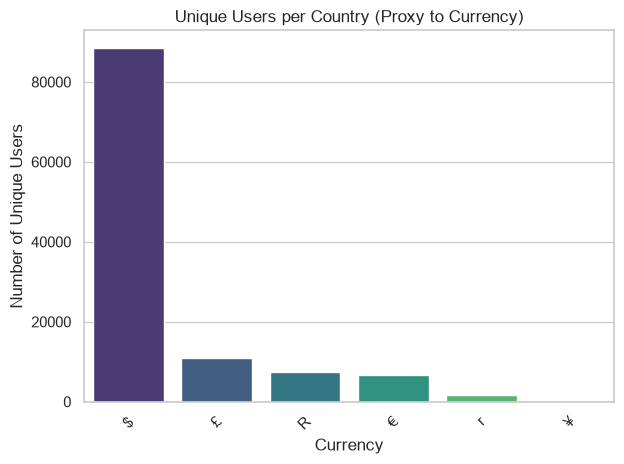

In [92]:
# 3.1 plot: unique users per country
users_per_currency = (
    df.groupby("currency")["user_id"]
    .nunique().sort_values(ascending=False)
    )

plt.Figure(figsize=(10, 5))
sns.barplot(
    x=users_per_currency.index,
    y=users_per_currency.values,
    palette="viridis",
    hue=users_per_currency.index,
    legend=False,
)
plt.title("Unique Users per Country (Proxy to Currency)")
plt.xlabel("Currency")
plt.ylabel("Number of Unique Users")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
# plt.savefig("Unique_users_per_currency.png")

## **Popularity of the APP**: Plot of number of unique users per day

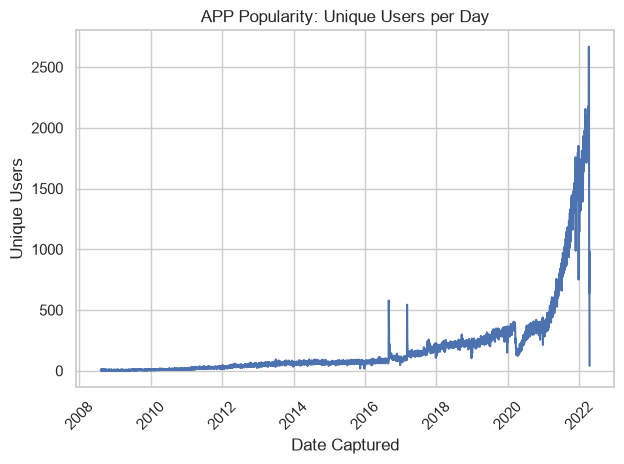

In [93]:
# Popularity of app
# Plot: unique users per day
df["date_captured_dt"] = pd.to_datetime(df["date_captured"], errors="coerce")

users_per_day = (
    df.groupby(df["date_captured_dt"].dt.date)["user_id"]
    .nunique()
    .reset_index()
)

plt.Figure(figsize=(12, 5))
plt.plot(
    users_per_day["date_captured_dt"],
    users_per_day["user_id"],
)
plt.title("APP Popularity: Unique Users per Day")
plt.xlabel("Date Captured")
plt.ylabel("Unique Users")
plt.xticks(rotation=45)
plt.tight_layout()
# plt.savefig("App_popularity_users_per_day.png")
plt.show()

## **Distribution of age of the vehicles per country**, Looking at the date it was refuelled.

#### *Ignoring unrealistic Vehicle Age*

C:\Users\adivh\AppData\Local\Temp\ipykernel_32140\2405811704.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date_fueled_dt"] = pd.to_datetime(df["date_fueled"], errors="coerce")
C:\Users\adivh\AppData\Local\Temp\ipykernel_32140\2405811704.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


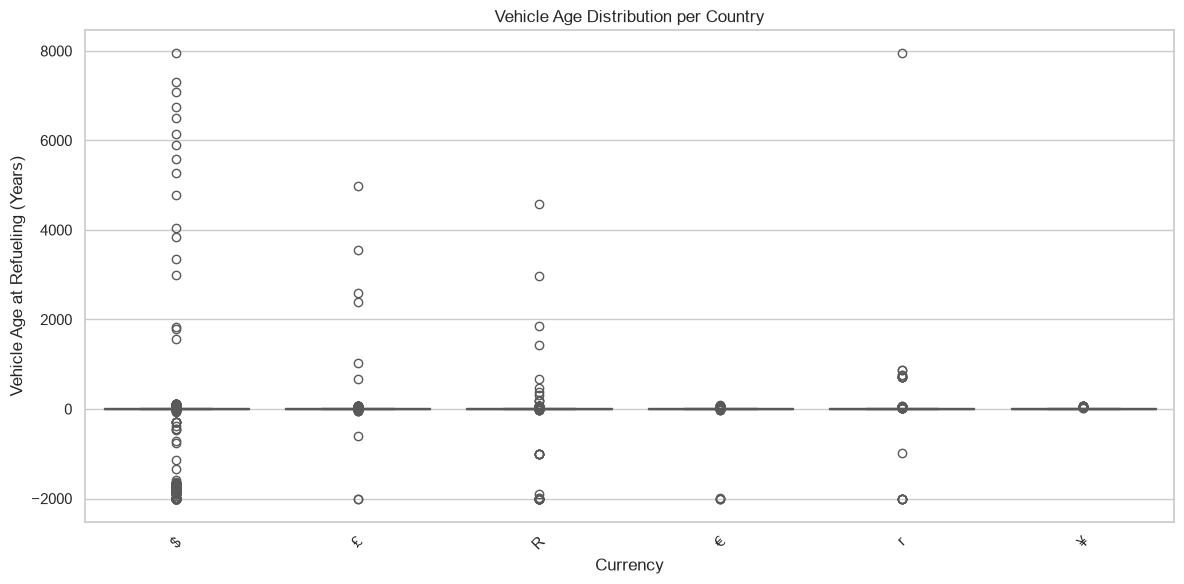

In [94]:
# 3. Distrtibution of car age
# Plot: car and refuel date

df["date_fueled_dt"] = pd.to_datetime(df["date_fueled"], errors="coerce")

df["fueling_year"] = df["date_fueled_dt"].dt.year
df["vehicle_age"] = df["fueling_year"] - df["car_year"]

plt.figure(figsize=(12, 6))
# Realistic age filter
# valid_age_df = df[(df["vehicle_age"] >= 0) & (df["vehicle_age"] <= 100)]

sns.boxplot(
    data=df,
    x="currency",
    y="vehicle_age",
    palette="Set2",
    legend=False,
)

plt.title("Vehicle Age Distribution per Country")
plt.xlabel("Currency")
plt.ylabel("Vehicle Age at Refueling (Years)")
plt.xticks(rotation=45)
plt.tight_layout()
# plt.savefig("vehicle_age_distribution.png")
plt.show()

#### *Limiting realistic Vehicle Age to 50 Years.*

C:\Users\adivh\AppData\Local\Temp\ipykernel_32140\691747628.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date_fueled_dt"] = pd.to_datetime(df["date_fueled"], errors="coerce")
C:\Users\adivh\AppData\Local\Temp\ipykernel_32140\691747628.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


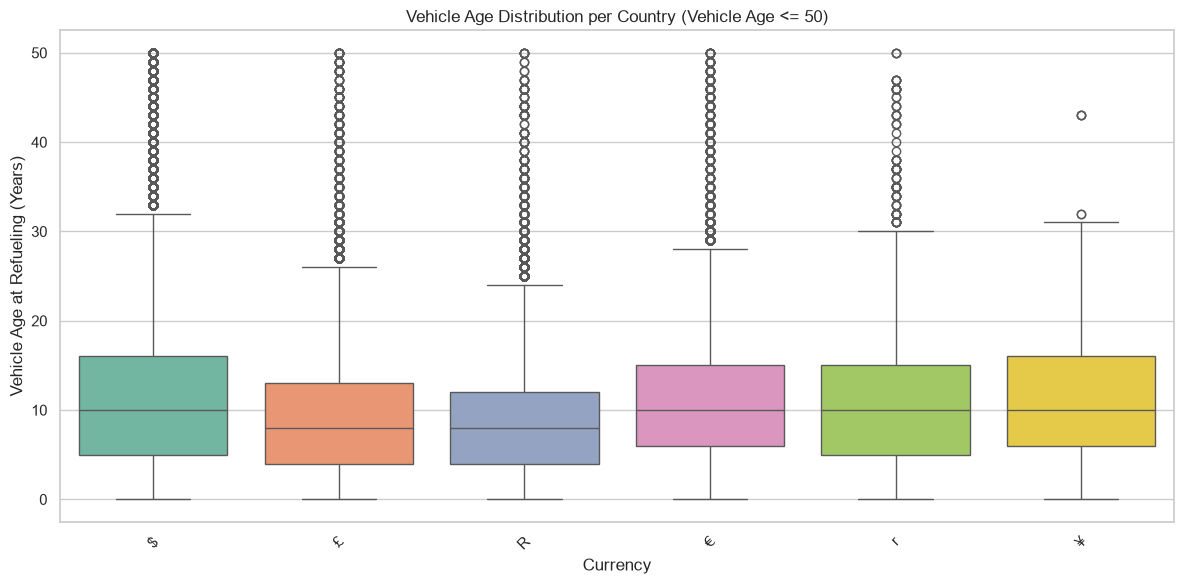

In [95]:
# 3. Distrtibution of car age
# Plot: car and refuel date

df["date_fueled_dt"] = pd.to_datetime(df["date_fueled"], errors="coerce")

df["fueling_year"] = df["date_fueled_dt"].dt.year
df["vehicle_age"] = df["fueling_year"] - df["car_year"]

plt.figure(figsize=(12, 6))
# Realistic age filter to maximum age = 50
valid_age_df = df[(df["vehicle_age"] >= 0) & (df["vehicle_age"] <= 50)]

sns.boxplot(
    data=valid_age_df,
    x="currency",
    y="vehicle_age",
    palette="Set2",
    legend=False,
)

plt.title("Vehicle Age Distribution per Country (Vehicle Age <= 50)")
plt.xlabel("Currency")
plt.ylabel("Vehicle Age at Refueling (Years)")
plt.xticks(rotation=45)
plt.tight_layout()
# plt.savefig("vehicle_age_distribution.png")
plt.show()

#### *Popular Cars by Make*

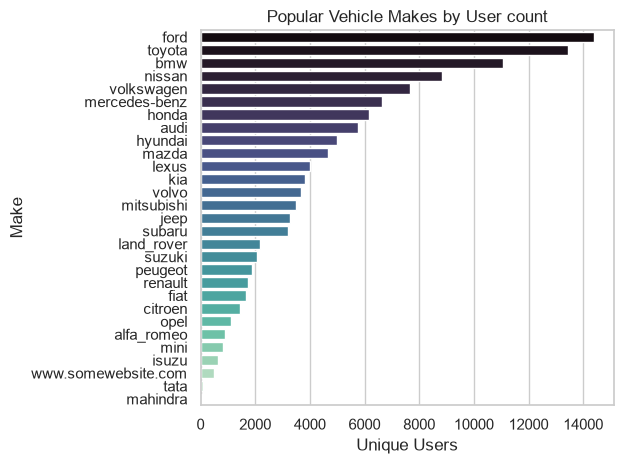

In [96]:
# 3.4 Most popular makes
popular_makes = (
    df.groupby("car_make")["user_id"].nunique().sort_values(ascending=False)
)

df["make_model"] = (
    df["car_make"].astype(str) + " " + df["car_model"].astype(str)
)

popular_models = (
    df.groupby("make_model")["user_id"].nunique().sort_values(ascending=False)
)

sns.barplot(
    x=popular_makes.values,
    y=popular_makes.index,
    hue=popular_makes.index,
    palette="mako",
    legend=False,
)
plt.title("Popular Vehicle Makes by User count")
plt.xlabel("Unique Users")
plt.ylabel("Make")
plt.tight_layout()
# plt.savefig("top_makes.png")
plt.show()

#### *Top 10 Popular Models*

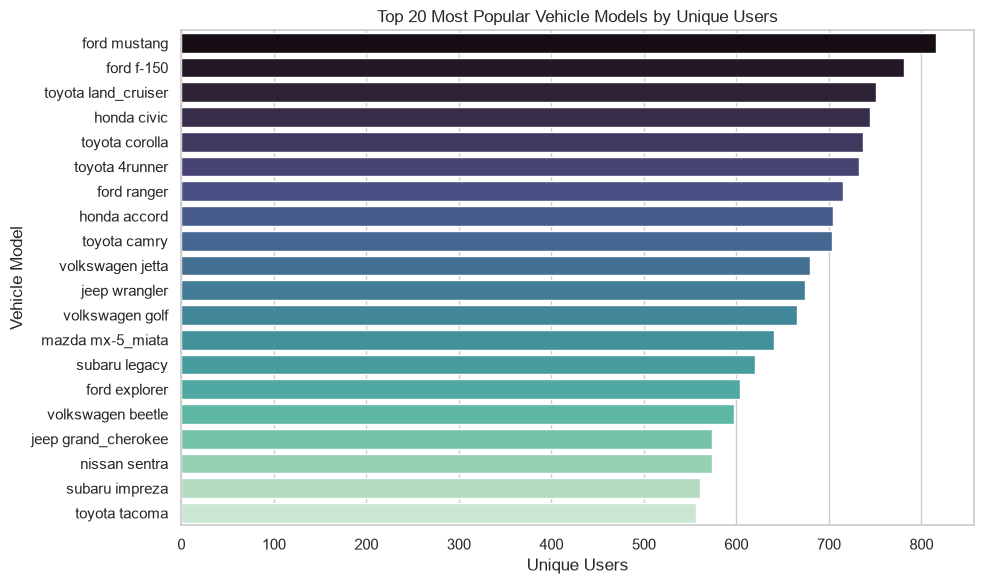

In [97]:
# 3.4 Most popular makes and models
df["make_model"] = (
    df["car_make"].astype(str) + " " + df["car_model"].astype(str)
)

# Limit to the top 10 most popular models by unique users
top_models = (
    df.groupby("make_model")["user_id"]
    .nunique()
    .sort_values(ascending=False).head(20)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_models.values,
    y=top_models.index,
    hue=top_models.index,  # Fixes Seaborn palette warning
    palette="mako",
    legend=False,
)
plt.title("Top 20 Most Popular Vehicle Models by Unique Users")
plt.xlabel("Unique Users")
plt.ylabel("Vehicle Model")
plt.tight_layout()
plt.show()